# PulmoSight 04 — Transfer Learning with EfficientNet-B0

In [1]:
import json, math, os, random, time
from collections import deque
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.io as tvio
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16
IMAGE_SIZE, MEAN, STD = 512, 0.449, 0.226
CLASSES = ["normal", "tb"]
SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

print(f"Project root : {ROOT}")
print(f"PyTorch      : {torch.__version__}")
print(f"Device       : {DEVICE} ({torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU'})")
print(f"AMP dtype    : {AMP_DTYPE}")

Project root : F:\Projects\pulmoSight\TB Project
PyTorch      : 2.11.0+cu128
Device       : cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
AMP dtype    : torch.bfloat16


In [2]:
def read_xray(path):
    """Decode a cached 8-bit grayscale PNG -> uint8 tensor [1, H, W]."""
    img = tvio.decode_image(tvio.read_file(str(path)), mode=tvio.ImageReadMode.GRAY)
    if img.shape[-2:] != (IMAGE_SIZE, IMAGE_SIZE):
        img = F.interpolate(img[None].float(), size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear",
                            antialias=True, align_corners=False)[0].round().clamp(0, 255).to(torch.uint8)
    return img


class XrayLoader:
    """Thread-pool batch loader.

    Windows notebooks cannot pickle notebook-defined Datasets into DataLoader worker
    processes, so we decode PNGs with threads (decoding releases the GIL) and do all
    augmentation on the GPU instead.
    """
    def __init__(self, frame, batch_size=32, shuffle=False, drop_last=False, threads=12, prefetch=6, seed=SEED):
        self.paths = [ROOT / p for p in frame["path"]]
        self.labels = frame["label"].to_numpy(dtype=np.int64)
        self.batch_size, self.shuffle, self.drop_last = batch_size, shuffle, drop_last
        self.threads, self.prefetch = threads, prefetch
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        n = len(self.paths)
        return n // self.batch_size if self.drop_last else math.ceil(n / self.batch_size)

    def __iter__(self):
        n = len(self.paths)
        order = self.rng.permutation(n) if self.shuffle else np.arange(n)
        batches = [order[i:i + self.batch_size] for i in range(0, n, self.batch_size)]
        if self.drop_last and len(batches[-1]) < self.batch_size:
            batches = batches[:-1]
        with ThreadPoolExecutor(self.threads) as pool:
            pending, it = deque(), iter(batches)
            submit = lambda b: (b, [pool.submit(read_xray, self.paths[i]) for i in b])
            for _ in range(self.prefetch):
                b = next(it, None)
                if b is not None:
                    pending.append(submit(b))
            while pending:
                b, futures = pending.popleft()
                nxt = next(it, None)
                if nxt is not None:
                    pending.append(submit(nxt))
                x = torch.stack([f.result() for f in futures])
                yield x, torch.from_numpy(self.labels[b])


def gpu_augment(x):
    """Random affine (+-7 deg, +-4% shift, 0.93-1.07 zoom) + brightness/contrast jitter, on GPU."""
    b, dev = x.size(0), x.device
    u = lambda: torch.rand(b, device=dev) * 2 - 1
    angle, scale = u() * math.radians(7), 1 + u() * 0.07
    tx, ty = u() * 0.08, u() * 0.08            # grid spans [-1, 1] -> 4% of the image
    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bright = 1 + u().view(b, 1, 1, 1) * 0.15
    contrast = 1 + u().view(b, 1, 1, 1) * 0.15
    x = x * bright
    m = x.mean(dim=(2, 3), keepdim=True)
    return ((x - m) * contrast + m).clamp(0, 1)


def prepare_batch(x, augment=False):
    x = x.to(DEVICE, non_blocking=True).float().div_(255)
    if augment:
        x = gpu_augment(x)
    return ((x - MEAN) / STD).contiguous(memory_format=torch.channels_last)


splits = pd.read_csv(ROOT / "splits" / "splits.csv")
train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df = splits[splits.split == "val"].reset_index(drop=True)
test_df = splits[splits.split == "test"].reset_index(drop=True)
print(splits.groupby(["split", "label"]).size().unstack().rename(columns=dict(enumerate(CLASSES))))

label  normal    tb
split              
test      861   820
train    6860  6585
val       850   809


In [3]:
def autocast():
    return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=DEVICE.type == "cuda")


@torch.no_grad()
def predict_logits(model, loader):
    model.eval()
    logits, labels = [], []
    for x, y in loader:
        with autocast():
            out = model(prepare_batch(x))
        logits.append(out.float().cpu()); labels.append(y)
    return torch.cat(logits).numpy(), torch.cat(labels).numpy()


def binary_metrics(logits, labels, threshold=0.5):
    p = torch.from_numpy(logits).softmax(1)[:, 1].numpy()
    pred = p >= threshold
    pos = labels == 1
    tp, tn = int((pred & pos).sum()), int((~pred & ~pos).sum())
    fp, fn = int((pred & ~pos).sum()), int((~pred & pos).sum())
    return {"auroc": float(roc_auc_score(labels, p)), "acc": (tp + tn) / len(labels),
            "sensitivity": tp / max(tp + fn, 1), "specificity": tn / max(tn + fp, 1)}


def fit(model, train_loader, val_loader, optimizer, scheduler, epochs, criterion, ckpt_path, meta,
        patience=6, history=None, stage="", before_epoch=None):
    """Train with early stopping on validation AUROC. Saves the best checkpoint to ckpt_path."""
    history = [] if history is None else history
    best = max([h["val_auroc"] for h in history], default=-1.0)
    bad = 0
    start = len(history) + 1
    for epoch in range(start, start + epochs):
        t0 = time.time()
        model.train()
        if before_epoch:
            before_epoch(model)
        loss_sum = torch.zeros((), device=DEVICE); correct = torch.zeros((), device=DEVICE); seen = 0
        for x, y in train_loader:
            x, y = prepare_batch(x, augment=True), y.to(DEVICE, non_blocking=True)
            with autocast():
                out = model(x)
            loss = criterion(out.float(), y)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * y.size(0); correct += (out.argmax(1) == y).sum(); seen += y.size(0)

        val_logits, val_labels = predict_logits(model, val_loader)
        val_loss = F.cross_entropy(torch.from_numpy(val_logits), torch.from_numpy(val_labels)).item()
        m = binary_metrics(val_logits, val_labels)
        row = {"epoch": epoch, "stage": stage, "train_loss": loss_sum.item() / seen, "train_acc": correct.item() / seen,
               "val_loss": val_loss, "val_acc": m["acc"], "val_auroc": m["auroc"],
               "val_sensitivity": m["sensitivity"], "val_specificity": m["specificity"],
               "lr": optimizer.param_groups[-1]["lr"], "seconds": time.time() - t0}
        history.append(row)
        flag = ""
        if m["auroc"] > best:
            best, bad, flag = m["auroc"], 0, "  * best, saved"
            torch.save({**meta, "state_dict": model.state_dict(), "epoch": epoch, "val_metrics": m}, ckpt_path)
        else:
            bad += 1
        print(f"Epoch {epoch:02d} {stage:>9} | train loss {row['train_loss']:.4f} acc {row['train_acc']:.3f} | "
              f"val loss {val_loss:.4f} acc {m['acc']:.3f} AUROC {m['auroc']:.4f} "
              f"sens {m['sensitivity']:.3f} spec {m['specificity']:.3f} | {row['seconds']:.0f}s{flag}")
        if bad >= patience:
            print(f"Early stopping: no AUROC improvement for {patience} epochs.")
            break
    return history


def plot_history(history, title):
    h = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    axes[0].plot(h.epoch, h.train_loss, "o-", label="train"); axes[0].plot(h.epoch, h.val_loss, "o-", label="val")
    axes[0].set(title="Loss", xlabel="epoch"); axes[0].legend()
    axes[1].plot(h.epoch, h.train_acc, "o-", label="train"); axes[1].plot(h.epoch, h.val_acc, "o-", label="val")
    axes[1].set(title="Accuracy", xlabel="epoch"); axes[1].legend()
    axes[2].plot(h.epoch, h.val_auroc, "o-", color="tab:green", label="val AUROC")
    axes[2].plot(h.epoch, h.val_sensitivity, "--", label="val sensitivity")
    axes[2].plot(h.epoch, h.val_specificity, "--", label="val specificity")
    best = h.loc[h.val_auroc.idxmax()]
    axes[2].axvline(best.epoch, color="gray", ls=":", label=f"best epoch {int(best.epoch)}")
    axes[2].set(title="Validation metrics", xlabel="epoch"); axes[2].legend()
    fig.suptitle(title, fontsize=14, weight="bold"); fig.tight_layout()
    return fig

## Build the model

In [4]:
from torchvision import models

def build_efficientnet_b0(pretrained=True):
    """ImageNet EfficientNet-B0 adapted to 1-channel X-rays (RGB stem filters summed)."""
    weights = models.EfficientNet_B0_Weights.DEFAULT if pretrained else None
    model = models.efficientnet_b0(weights=weights)
    stem = model.features[0][0]
    gray = nn.Conv2d(1, stem.out_channels, stem.kernel_size, stem.stride, stem.padding, bias=False)
    with torch.no_grad():
        gray.weight.copy_(stem.weight.sum(dim=1, keepdim=True))
    model.features[0][0] = gray
    model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, 2))
    return model

In [5]:
seed_everything()
model = build_efficientnet_b0(pretrained=True).to(DEVICE, memory_format=torch.channels_last)
count = lambda ps: sum(p.numel() for p in ps)
print(f"Total parameters     : {count(model.parameters()):,}")
print(f"Backbone (features)  : {count(model.features.parameters()):,}")
print(f"Classifier head      : {count(model.classifier.parameters()):,}")
print("\nNew grayscale stem:", model.features[0][0])

from torch.utils.flop_counter import FlopCounterMode
with FlopCounterMode(display=False) as fc:
    model.eval()(torch.zeros(1, 1, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
print(f"GFLOPs per 512x512 image: {fc.get_total_flops() / 2e9:.2f} (multiply-adds)")

W1113 16:46:55.890000 42344 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Total parameters     : 4,009,534
Backbone (features)  : 4,006,972
Classifier head      : 2,562

New grayscale stem: Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)


GFLOPs per 512x512 image: 1.97 (multiply-adds)


### The pre-trained stem filters (ImageNet → grayscale)

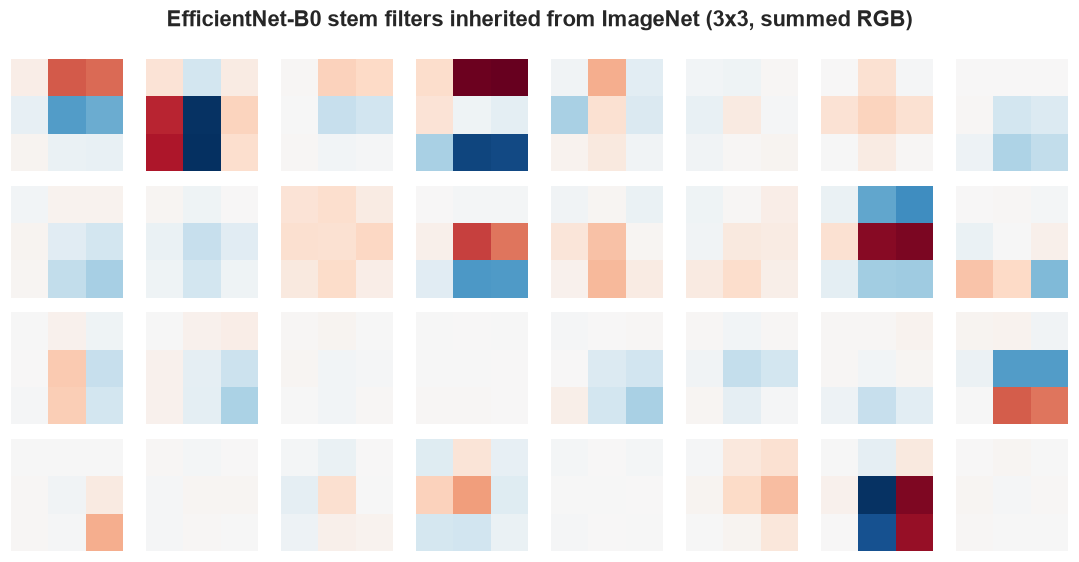

In [6]:
w = model.features[0][0].weight.detach().float().cpu()[:, 0]
fig, axes = plt.subplots(4, 8, figsize=(10, 5.2))
for ax, k in zip(axes.flat, w):
    ax.imshow(k, cmap="RdBu_r", vmin=-w.abs().max(), vmax=w.abs().max()); ax.axis("off")
plt.suptitle("EfficientNet-B0 stem filters inherited from ImageNet (3x3, summed RGB)", weight="bold"); plt.tight_layout(); plt.show()

## Training configuration

In [7]:
CONFIG = dict(arch="efficientnet_b0", warmup_epochs=2, finetune_epochs=20, batch_size=16,
              head_lr=1e-3, backbone_lr=3e-4, weight_decay=0.01, label_smoothing=0.05, patience=6)
RUN_DIR = ROOT / "models" / "efficientnet_b0"
RUN_DIR.mkdir(parents=True, exist_ok=True)
train_loader = XrayLoader(train_df, CONFIG["batch_size"], shuffle=True, drop_last=True)
val_loader = XrayLoader(val_df, 64)
criterion = nn.CrossEntropyLoss(label_smoothing=CONFIG["label_smoothing"])
meta = {"arch": "efficientnet_b0", "classes": CLASSES, "image_size": IMAGE_SIZE, "mean": MEAN, "std": STD, "config": CONFIG}
history = []

## Stage 1 — train only the classifier head

In [8]:
for p in model.features.parameters():
    p.requires_grad = False
print(f"Trainable parameters: {count(p for p in model.parameters() if p.requires_grad):,}")

optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"])
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=CONFIG["head_lr"], epochs=CONFIG["warmup_epochs"],
                                                steps_per_epoch=len(train_loader), pct_start=0.1)
freeze_bn = lambda m: m.features.eval()   # keep ImageNet BatchNorm statistics while frozen
t_start = time.time()
history = fit(model, train_loader, val_loader, optimizer, scheduler, CONFIG["warmup_epochs"], criterion,
              RUN_DIR / "best.pth", meta, patience=99, history=history, stage="head-only", before_epoch=freeze_bn)

Trainable parameters: 2,562


Epoch 01 head-only | train loss 0.5920 acc 0.689 | val loss 0.5141 acc 0.745 AUROC 0.8339 sens 0.786 spec 0.706 | 127s  * best, saved


Epoch 02 head-only | train loss 0.5410 acc 0.739 | val loss 0.5005 acc 0.759 AUROC 0.8396 sens 0.719 spec 0.798 | 35s  * best, saved


## Stage 2 — unfreeze and fine-tune everything

In [9]:
for p in model.features.parameters():
    p.requires_grad = True
print(f"Trainable parameters: {count(p for p in model.parameters() if p.requires_grad):,}")

def groups(module, lr):
    params = list(module.parameters())
    return [{"params": [p for p in params if p.ndim > 1], "lr": lr, "weight_decay": CONFIG["weight_decay"]},
            {"params": [p for p in params if p.ndim <= 1], "lr": lr, "weight_decay": 0.0}]

optimizer = torch.optim.AdamW(groups(model.features, CONFIG["backbone_lr"]) + groups(model.classifier, CONFIG["head_lr"]))
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=[CONFIG["backbone_lr"]] * 2 + [CONFIG["head_lr"]] * 2,
    epochs=CONFIG["finetune_epochs"], steps_per_epoch=len(train_loader), pct_start=0.1)
history = fit(model, train_loader, val_loader, optimizer, scheduler, CONFIG["finetune_epochs"], criterion,
              RUN_DIR / "best.pth", meta, patience=CONFIG["patience"], history=history, stage="fine-tune")
train_minutes = (time.time() - t_start) / 60
(RUN_DIR / "history.json").write_text(json.dumps(history, indent=2))
print(f"\nTotal training time: {train_minutes:.1f} min")

Trainable parameters: 4,009,534


Epoch 03 fine-tune | train loss 0.5527 acc 0.730 | val loss 0.4790 acc 0.777 AUROC 0.8824 sens 0.860 spec 0.698 | 162s  * best, saved


Epoch 04 fine-tune | train loss 0.4885 acc 0.790 | val loss 0.4582 acc 0.797 AUROC 0.8828 sens 0.670 spec 0.919 | 116s  * best, saved


Epoch 05 fine-tune | train loss 0.4394 acc 0.823 | val loss 0.4000 acc 0.821 AUROC 0.9090 sens 0.867 spec 0.778 | 116s  * best, saved


Epoch 06 fine-tune | train loss 0.3921 acc 0.847 | val loss 0.3364 acc 0.847 AUROC 0.9308 sens 0.763 spec 0.927 | 116s  * best, saved


Epoch 07 fine-tune | train loss 0.3639 acc 0.865 | val loss 0.3769 acc 0.838 AUROC 0.9160 sens 0.747 spec 0.925 | 116s


... (4 outputs left out)

Epoch 12 fine-tune | train loss 0.2381 acc 0.941 | val loss 0.3771 acc 0.854 AUROC 0.9292 sens 0.881 spec 0.828 | 116s


Epoch 13 fine-tune | train loss 0.2115 acc 0.956 | val loss 0.3879 acc 0.859 AUROC 0.9190 sens 0.802 spec 0.913 | 119s


Epoch 14 fine-tune | train loss 0.1895 acc 0.968 | val loss 0.4080 acc 0.867 AUROC 0.9150 sens 0.817 spec 0.914 | 119s


Epoch 15 fine-tune | train loss 0.1708 acc 0.976 | val loss 0.4141 acc 0.860 AUROC 0.9150 sens 0.805 spec 0.913 | 129s
Early stopping: no AUROC improvement for 6 epochs.

Total training time: 29.0 min


## Learning curves

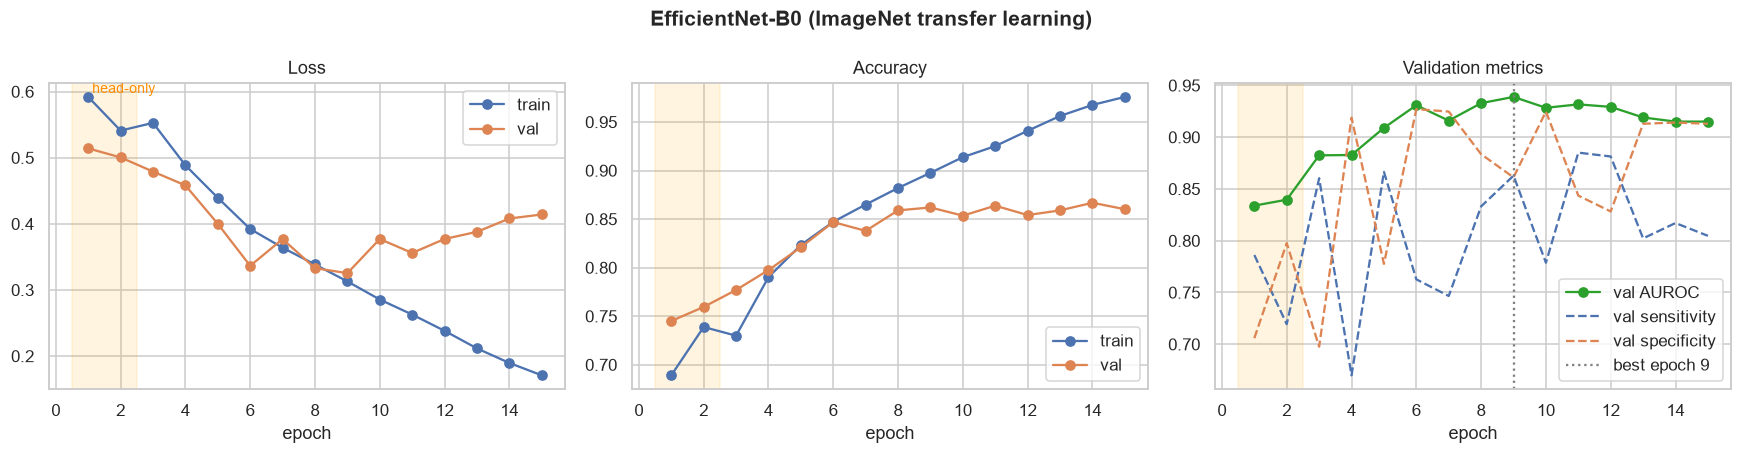

Best epoch 9 (fine-tune): val AUROC 0.9389, acc 0.862, sens 0.863, spec 0.861


In [10]:
fig = plot_history(history, "EfficientNet-B0 (ImageNet transfer learning)")
for ax in fig.axes:
    ax.axvspan(0.5, CONFIG["warmup_epochs"] + 0.5, color="orange", alpha=0.12)
fig.axes[0].text(1, fig.axes[0].get_ylim()[1], " head-only", va="top", fontsize=9, color="darkorange")
plt.savefig(RUN_DIR / "learning_curves.png", dpi=150, bbox_inches="tight"); plt.show()
best = max(history, key=lambda h: h["val_auroc"])
print(f"Best epoch {best['epoch']} ({best['stage']}): val AUROC {best['val_auroc']:.4f}, acc {best['val_acc']:.3f}, "
      f"sens {best['val_sensitivity']:.3f}, spec {best['val_specificity']:.3f}")

## Validation check of the best checkpoint

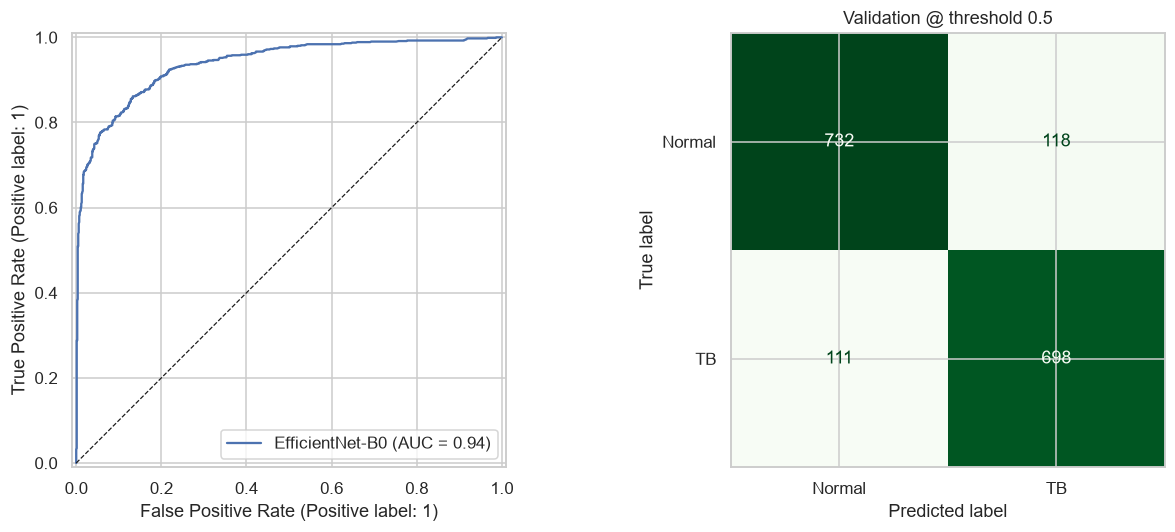

{'auroc': 0.9388700647131536, 'acc': 0.861965039180229, 'sensitivity': 0.8627935723114957, 'specificity': 0.8611764705882353}


In [11]:
ckpt = torch.load(RUN_DIR / "best.pth", map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["state_dict"])
val_logits, val_labels = predict_logits(model, val_loader)
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
p = torch.from_numpy(val_logits).softmax(1)[:, 1].numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(val_labels, p, ax=axes[0], name="EfficientNet-B0"); axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
ConfusionMatrixDisplay.from_predictions(val_labels, p >= 0.5, display_labels=["Normal", "TB"], cmap="Greens", ax=axes[1], colorbar=False)
axes[1].set_title("Validation @ threshold 0.5"); plt.tight_layout(); plt.show()
print(binary_metrics(val_logits, val_labels))

### How much did fine-tuning change the stem filters?

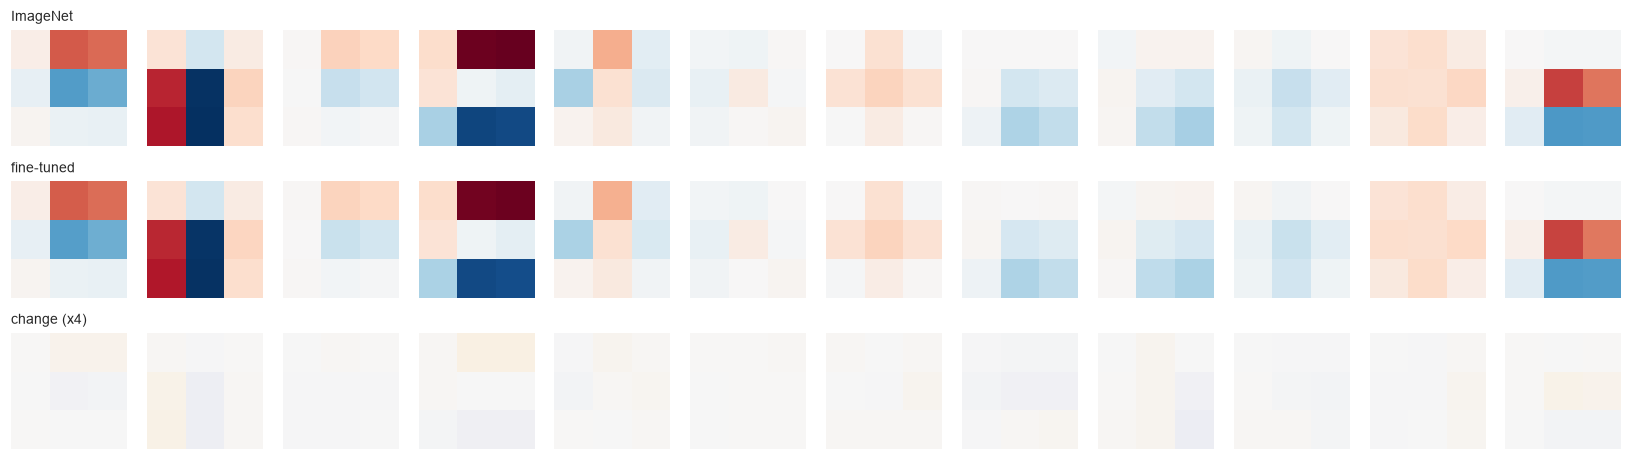

Mean relative change of stem weights: 2.1%


In [12]:
original = build_efficientnet_b0(pretrained=True).features[0][0].weight.detach()[:, 0]
tuned = model.features[0][0].weight.detach().float().cpu()[:, 0]
fig, axes = plt.subplots(3, 12, figsize=(15, 4.4))
lim = original.abs().max()
for i in range(12):
    axes[0, i].imshow(original[i], cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[1, i].imshow(tuned[i], cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[2, i].imshow(tuned[i] - original[i], cmap="PuOr", vmin=-lim / 4, vmax=lim / 4)
for ax in axes.flat: ax.axis("off")
for r, t in enumerate(["ImageNet", "fine-tuned", "change (x4)"]): axes[r, 0].set_title(t, fontsize=9, loc="left")
plt.tight_layout(); plt.show()
print(f"Mean relative change of stem weights: {((tuned - original).norm() / original.norm()).item():.1%}")

In [13]:
summary = {"arch": "efficientnet_b0", "parameters": count(model.parameters()), "best_epoch": best["epoch"],
           "best_val_auroc": best["val_auroc"], "train_minutes": train_minutes, "epochs_run": len(history)}
(RUN_DIR / "summary.json").write_text(json.dumps(summary, indent=2))
summary

{'arch': 'efficientnet_b0',
 'parameters': 4009534,
 'best_epoch': 9,
 'best_val_auroc': 0.9388700647131536,
 'train_minutes': 28.95530570745468,
 'epochs_run': 15}